# Step 4. Apply

*With ngff-zarr.*

**Goal:** use the registration from the scene, without writing a resampled copy. `pair.ozx` is enough: the two images
and the transformation travel together.

In [ ]:
import ngff_zarr as nz
from common import DATA, dice, ncc, scene_fields, show

SCENE = "../output/pair.ozx"
scene = nz.NgffScene.from_ome_zarr(SCENE)
T = scene.coordinateTransformations[0]
fixed, moving = scene.images["fixed"].images[0], scene.images["moving"].images[0]
moved = nz.resample(T, fixed, moving, fields=scene_fields(SCENE, T))  # lazy: described block by block, nothing read yet
moved.data

dask.array<ngff-zarr-resample, shape=(50, 680, 535), dtype=uint16, chunksize=(50, 128, 128), chunktype=numpy.ndarray>

`moved` is the moving image drawn on the fixed grid: for each voxel $x$ of the fixed image, the moving image read at
$T(x)$. Computing one plane reads only the part of the moving image that plane needs. Where the two rounds agree,
green and magenta turn white:

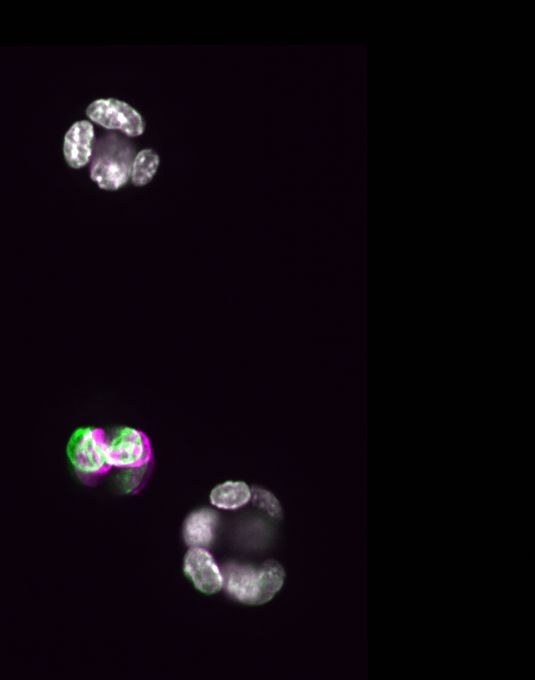

In [ ]:
show(fixed.data[25], moved.data[25])

"Before" is the same call through the identity, the moving image on the fixed grid as the two sit in space. And the
scene keeps the pyramids: the same transformation applies at any level, the whole organoid at the coarsest in a
moment.

In [ ]:
from ngff_zarr.v06.zarr_metadata import Identity

unmoved = nz.resample(Identity(input=T.input, output=T.output), fixed, moving)
print(f"correlation on one plane: {ncc(fixed.data[25], unmoved.data[25]):.2f} -> {ncc(fixed.data[25], moved.data[25]):.2f}")
coarse = nz.resample(T, scene.images["fixed"].images[2], scene.images["moving"].images[2], fields=scene_fields(SCENE, T))
print(f"at the coarsest level, {coarse.data.shape}: {ncc(scene.images['fixed'].images[2].data[12], coarse.data[12]):.2f}")

correlation on one plane: -0.06 -> 0.90
at the coarsest level, (50, 170, 133): 0.98


## The same transformation carries everything else

The nuclei of each round, with an interpolation that keeps their labels. The measure is the Dice of the two nuclei
masks, all nuclei against all nuclei: how well the nuclei overlap, not whether each nucleus found its own.

In [ ]:
nuclei_fixed = nz.from_ngff_zarr(f"{DATA}/fixed_nuclei.ome.zarr").images[0]
nuclei_moving = nz.from_ngff_zarr(f"{DATA}/moving_nuclei.ome.zarr").images[0]
carried = nz.resample(T, fixed, nuclei_moving, interpolator="label_image", fields=scene_fields(SCENE, T))
print(f"nuclei mask Dice: {dice(nuclei_fixed.data, nuclei_moving.data):.2f} -> {dice(nuclei_fixed.data, carried.data):.2f}")

nuclei mask Dice: 0.00 -> 0.92


## Map points

A landmark goes through the same transformation, without any image: a point of the fixed image, in micrometers and in
the order z, y, x, comes out at its place in the moving image.

In [ ]:
!echo '[[15.0, 73.0, 58.0]]' > ../output/points.json
!ngff-zarr transform-points ../output/pair.ozx ../output/points.json

{"dims": ["z", "y", "x"], "points": [[16.36255275177611, 63.190992652133474, 94.37253238054316]]}


## See it in napari

A viewer that reads RFC-5 does the same on its own. napari-ome-zarr opens the scene and places the moving image through
the affine itself: the two rounds in one view, nothing written. Scroll the planes, zoom into the full resolution. A
`displacements` field is not in napari-ome-zarr yet: with a deformable preset, the pictures above are the way to look.

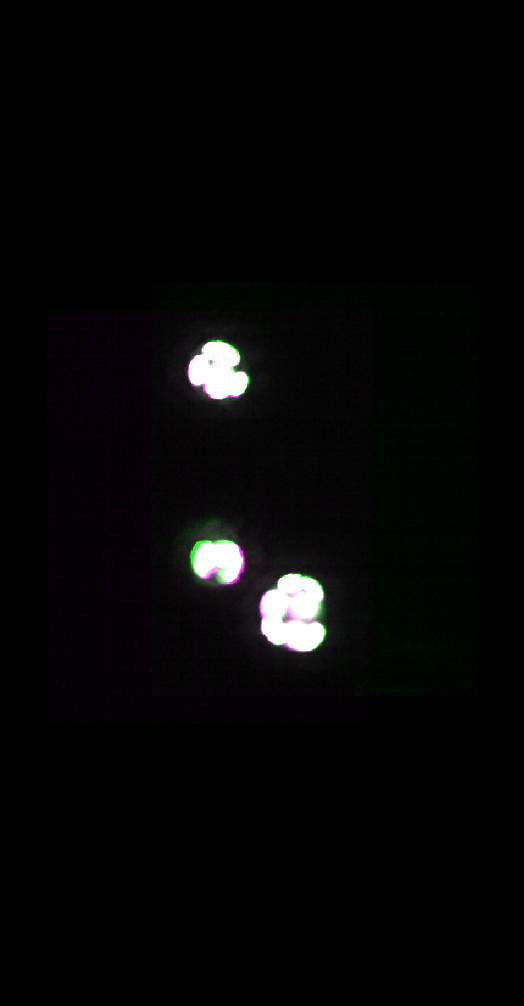

In [ ]:
import napari
from napari.utils import nbscreenshot

viewer = napari.Viewer()
viewer.open("../output/pair.ome.zarr", plugin="napari-ome-zarr")  # the scene as a folder, written beside pair.ozx
for layer, colormap in zip(viewer.layers, ("green", "magenta")):
    layer.colormap, layer.blending = colormap, "additive"
viewer.dims.set_point(0, 15); viewer.window.resize(560, 500); viewer.reset_view()
nbscreenshot(viewer, canvas_only=True)

## You are done

You started from two images of a public plate, and you have one file holding them and their registration, in the form
RFC-5 gives every OME-Zarr reader to apply: ngff-zarr applies it, napari shows it. **[Going further](../going-further.md)**:
your own pair, 2-D images, larger images.